# B2 — Correlation-prune the pilot frame; propose the surviving metric vector

Resolves issue **#26** (part of the Phase-B map, **#23**). This is the auditable artifact the
ticket asks for: it regenerates, from the committed pilot frame, the measured evidence behind
B2's proposed metric vector.

**What this notebook does, in plain terms.** Every one of the 15,000 pilot windows already carries
a score for nine terrain metrics (produced by `python -m dataset.pilot`, issue #24, at the Gate-A3
*production* resolutions). Here we ask two standard questions of that table:

1. **Spearman rank-correlation** — for each *pair* of metrics, "when one metric ranks a window high,
   does the other rank it high too?" Scored −1 (perfect opposite) … 0 (unrelated) … +1 (identical
   ordering). It is *rank*-based: it only looks at the ordering of windows, not the raw numbers, so
   any monotonic transform (log, rank) leaves it unchanged. **Prune rule (from the ticket): any group
   at |ρ| ≥ 0.90 says the same thing twice — keep one representative, drop the rest.**
2. **PCA (principal component analysis)** — "how many genuinely *independent directions* of variation
   live in this table?" Redundant metrics collapse into one direction; an independent metric earns its
   own. A cross-check on the pairwise view.

Plus a **degeneracy** check per metric (is a column *dead* — the same value for nearly every window —
so it cannot tell windows apart, regardless of how independent it looks?).

The **decisions** (which metric represents a redundant block, whether a degeneracy verdict holds) are
judgement calls made with a human via `/grilling` + `/domain-modeling`; they are recorded in the final
section, with their reasoning, so the notebook is self-explaining.

> Provenance: pilot frame `docs/research/pilot-frame-per-window.csv` (code `dabd6e1-dirty`, snapshot
> `2026-07-20`, seed `0xdeae`). Re-run top-to-bottom to refresh — nothing here is hand-edited.

In [1]:
import csv
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

# Locate the pilot frame regardless of the working directory the notebook runs from.
ROOT = Path.cwd()
while not (ROOT / "docs/research/pilot-frame-per-window.csv").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
CSV = ROOT / "docs/research/pilot-frame-per-window.csv"

# The nine metric columns, in the order dataset.metrics.METRICS defines them.
METRICS = [
    "local_relief", "slope_mean", "slope_std", "elevation_relief_ratio",
    "mean_elevation", "texture", "normals_dispersion", "geomorphon_entropy",
    "tpi_proxy",
]

with open(CSV) as f:
    r = csv.reader(f)
    header = next(r)
    rows = list(r)

col_ix = {m: header.index(m) for m in METRICS}
n = len(rows)
data = {}
for m in METRICS:
    j = col_ix[m]
    x = np.empty(n, dtype=float)
    for i, row in enumerate(rows):
        v = row[j]
        x[i] = np.nan if v in ("", "nan") else float(v)
    data[m] = x

print(f"pilot frame: {n:,} windows x {len(METRICS)} metrics")
for m in METRICS:
    ndef = int(np.sum(~np.isnan(data[m])))
    print(f"  {m:<24} defined on {ndef:,} windows"
          + ("" if ndef == n else f"  ({n - ndef:,} NaN)"))

pilot frame: 15,000 windows x 9 metrics
  local_relief             defined on 15,000 windows
  slope_mean               defined on 14,989 windows  (11 NaN)
  slope_std                defined on 14,989 windows  (11 NaN)
  elevation_relief_ratio   defined on 14,882 windows  (118 NaN)
  mean_elevation           defined on 15,000 windows
  texture                  defined on 15,000 windows
  normals_dispersion       defined on 14,989 windows  (11 NaN)
  geomorphon_entropy       defined on 15,000 windows
  tpi_proxy                defined on 10,749 windows  (4,251 NaN)


## 1. Spearman rank-correlation matrix

Spearman ρ = ordinary (Pearson) correlation computed on the **average-rank transform** of each column
(ties share their mean rank). We compute it **pairwise-complete**: each pair uses only the windows
where *both* metrics are defined, re-ranking within that overlap, so a column with NaNs (`tpi_proxy`,
`elevation_relief_ratio`, the slope family) never poisons a pair it isn't in.

In [2]:
def avg_rank(x):
    # Average (tie-corrected) ranks of the non-NaN entries; NaN preserved in place.
    out = np.full(x.shape, np.nan)
    ok = ~np.isnan(x)
    v = x[ok]
    order = np.argsort(v, kind="mergesort")
    sv = v[order]
    ranks = np.empty(len(v))
    i = 0
    while i < len(v):
        k = i
        while k + 1 < len(v) and sv[k + 1] == sv[i]:
            k += 1
        ranks[order[i:k + 1]] = (i + k) / 2.0 + 1.0   # 1-based mean rank over the tie run
        i = k + 1
    out[ok] = ranks
    return out


def spearman(a, b):
    # Pairwise-complete Spearman rho between two columns.
    ok = ~np.isnan(a) & ~np.isnan(b)
    rx, ry = avg_rank(a[ok]), avg_rank(b[ok])
    rx = rx - rx.mean()
    ry = ry - ry.mean()
    denom = np.sqrt((rx * rx).sum() * (ry * ry).sum())
    return (rx * ry).sum() / denom if denom else np.nan


M = len(METRICS)
S = np.eye(M)
for i in range(M):
    for k in range(i + 1, M):
        S[i, k] = S[k, i] = spearman(data[METRICS[i]], data[METRICS[k]])

# Print the matrix.
print("Spearman rho (pairwise-complete):\n")
print(" " * 24 + "".join(f"{m[:8]:>9}" for m in METRICS))
for i, m in enumerate(METRICS):
    print(f"{m:>24}" + "".join(f"{S[i, k]:9.3f}" for k in range(M)))

Spearman rho (pairwise-complete):

                         local_re slope_me slope_st elevatio mean_ele  texture normals_ geomorph tpi_prox
            local_relief    1.000    0.814    0.804   -0.113    0.256    0.538    0.806   -0.034   -0.009
              slope_mean    0.814    1.000    0.953   -0.110    0.122    0.852    0.986    0.247   -0.008
               slope_std    0.804    0.953    1.000   -0.208    0.050    0.785    0.986    0.207   -0.049
  elevation_relief_ratio   -0.113   -0.110   -0.208    1.000    0.181   -0.101   -0.160    0.007    0.410
          mean_elevation    0.256    0.122    0.050    0.181    1.000    0.112    0.094   -0.018    0.106
                 texture    0.538    0.852    0.785   -0.101    0.112    1.000    0.838    0.442   -0.000
      normals_dispersion    0.806    0.986    0.986   -0.160    0.094    0.838    1.000    0.233   -0.024
      geomorphon_entropy   -0.034    0.247    0.207    0.007   -0.018    0.442    0.233    1.000   -0.027
           

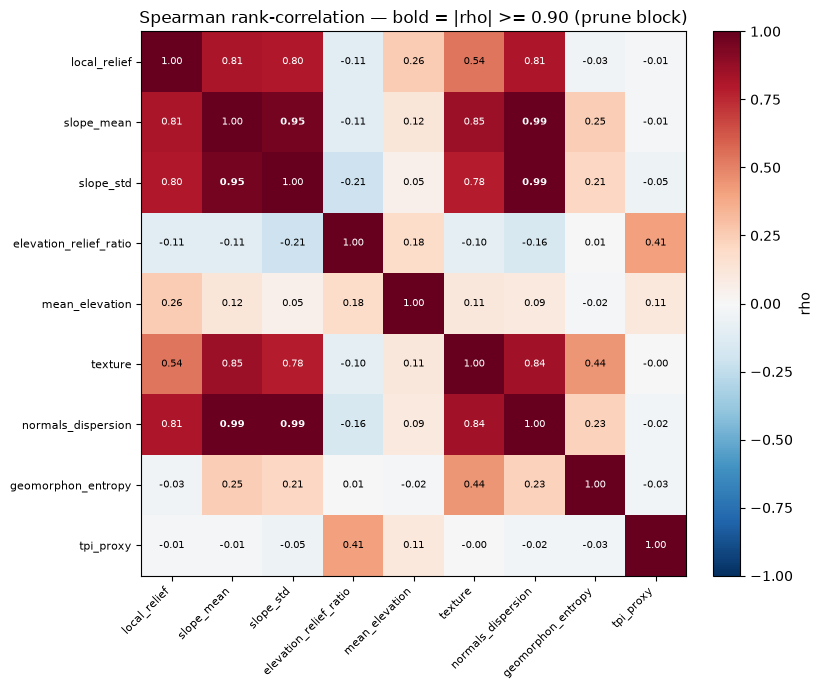

In [3]:
# Heatmap of the matrix — the 0.90 prune line is the story.
fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(S, vmin=-1, vmax=1, cmap="RdBu_r")
ax.set_xticks(range(M)); ax.set_xticklabels(METRICS, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(M)); ax.set_yticklabels(METRICS, fontsize=8)
for i in range(M):
    for k in range(M):
        strong = abs(S[i, k]) >= 0.90 and i != k
        ax.text(k, i, f"{S[i, k]:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(S[i, k]) > 0.55 else "black",
                fontweight="bold" if strong else "normal")
ax.set_title("Spearman rank-correlation — bold = |rho| >= 0.90 (prune block)")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="rho")
fig.tight_layout()
plt.show()

### Prune blocks at |ρ| ≥ 0.90

The mechanical rule fires only where a pair is at or above 0.90. Everything below is *strong but
survivable* — related, not redundant.

In [4]:
print("=== |rho| >= 0.90  (prune blocks — keep ONE representative) ===")
block_pairs = []
for i in range(M):
    for k in range(i + 1, M):
        if abs(S[i, k]) >= 0.90:
            block_pairs.append((METRICS[i], METRICS[k], S[i, k]))
            print(f"  {METRICS[i]:>24}  --  {METRICS[k]:<24}  rho = {S[i, k]:.3f}")

print("\n=== |rho| in [0.70, 0.90)  (strong, but below the prune line -> both survive) ===")
for i in range(M):
    for k in range(i + 1, M):
        if 0.70 <= abs(S[i, k]) < 0.90:
            print(f"  {METRICS[i]:>24}  --  {METRICS[k]:<24}  rho = {S[i, k]:.3f}")

=== |rho| >= 0.90  (prune blocks — keep ONE representative) ===
                slope_mean  --  slope_std                 rho = 0.953
                slope_mean  --  normals_dispersion        rho = 0.986
                 slope_std  --  normals_dispersion        rho = 0.986

=== |rho| in [0.70, 0.90)  (strong, but below the prune line -> both survive) ===
              local_relief  --  slope_mean                rho = 0.814
              local_relief  --  slope_std                 rho = 0.804
              local_relief  --  normals_dispersion        rho = 0.806
                slope_mean  --  texture                   rho = 0.852
                 slope_std  --  texture                   rho = 0.785
                   texture  --  normals_dispersion        rho = 0.838


**Reading it.** One block forms at ≥ 0.90: **`{slope_mean, slope_std, normals_dispersion}`** (ρ 0.95–0.99)
— three names for essentially one ordering of windows. Notably `normals_dispersion` ↔ `slope_mean` = 0.986:
because Spearman is rank-based, **no log/rank transform can undo this** (a transform re-scales values but
keeps their order, and the order is what's redundant). This *refutes* the Phase-A hypothesis that
`normals_dispersion` "tracks curvature, not steepness, so it's independent." It is dropped on **redundancy**.

`local_relief` ↔ `slope_mean` = 0.814 sits in the *strong-but-survivable* band — related (rugged places are
both steep and tall) but under the line, so it does **not** force a keep-one.

## 2. Degeneracy diagnostics

Redundancy is not the only way a metric fails. A **degenerate** column reads (nearly) the same value for
almost every window — it is *alive* only if it can tell windows apart. `zero_frac` = share reading exactly
0; `max_tie_frac` = share sharing the single most common value (a dead column would be tens of percent);
`skew` = tail direction (big + = long right tail; − = long left tail).

In [5]:
print(f"{'metric':>24} {'n':>7} {'zero_frac':>10} {'max_tie':>9} "
      f"{'p10':>10} {'p50':>10} {'p90':>10} {'skew':>7}")
for m in METRICS:
    v = data[m][~np.isnan(data[m])]
    zero_frac = float(np.mean(v == 0.0))
    _, counts = np.unique(v, return_counts=True)
    max_tie = counts.max() / len(v)
    p10, p50, p90 = np.percentile(v, [10, 50, 90])
    sd = v.std()
    skew = float(np.mean(((v - v.mean()) / sd) ** 3)) if sd else np.nan
    print(f"{m:>24} {len(v):>7,} {zero_frac:>10.4f} {max_tie:>9.4f} "
          f"{p10:>10.4g} {p50:>10.4g} {p90:>10.4g} {skew:>7.2f}")

                  metric       n  zero_frac   max_tie        p10        p50        p90    skew
            local_relief  15,000     0.0079    0.0079      10.88      70.42      406.5    3.58
              slope_mean  14,989     0.0075    0.0075     0.6971      2.113      10.47    2.48
               slope_std  14,989     0.0075    0.0075     0.5098      1.943      7.348    1.39
  elevation_relief_ratio  14,882     0.0000    0.0011     0.2546     0.4371     0.5908   -0.13
          mean_elevation  15,000     0.0000    0.0075      34.76      453.4       1978    1.89
                 texture  15,000     0.0185    0.0185   0.001535    0.06823     0.2933    1.43
      normals_dispersion  14,989     0.0075    0.0075  0.0001122   0.001263    0.02406    4.33
      geomorphon_entropy  15,000     0.0083    0.0083      1.256      2.438      2.975   -1.36
               tpi_proxy  10,749     0.0069    0.0069     -26.45     -0.358      18.71    0.60


**Reading it.**

- **`geomorphon_entropy` is NOT degenerate here.** Only 0.8% zeros, a real spread (p10 1.26 → p90 2.98),
  moderate ρ (0.44 with `texture`) — not the "zero-inflated flat tail" Phase A predicted from the flat,
  band-local A3 samples. On this *cell-balanced* frame (which includes the world's mountains) it has room
  to breathe. This **refutes** the Phase-A degeneracy verdict → it is **kept** (see PCA: it owns PC3).
- **`normals_dispersion` is degenerate in raw range** (skew +4.3, median 0.0013 — crushed near zero),
  confirming Phase A on that point. But it is *also* redundant (§1), and redundancy is the decisive strike:
  a transform could stretch its range but not change its ordering relative to slope. Dropped either way.
- `local_relief`, `slope_mean`, `mean_elevation` carry long right tails (skew +1.9 … +3.6) — the transform
  question of §4. `elevation_relief_ratio` (≈symmetric) and `geomorphon_entropy` (left-skewed) do not want a log.

## 3. PCA — how many independent directions?

PCA on the **standardized ranks** of the eight survival-candidate metrics (`tpi_proxy` excluded — its fate
is B3's flat-wet call, not this matrix), over the windows where all eight are defined. Working on *ranks*
keeps PCA consistent with the rank-based prune rule and immune to the raw-scale skew.

In [6]:
pca_metrics = [m for m in METRICS if m != "tpi_proxy"]
Rank = np.column_stack([avg_rank(data[m]) for m in pca_metrics])
complete = ~np.isnan(Rank).any(axis=1)
Rc = Rank[complete]
Z = (Rc - Rc.mean(0)) / Rc.std(0)

C = np.corrcoef(Z, rowvar=False)
eigval, eigvec = np.linalg.eigh(C)
order = np.argsort(eigval)[::-1]
eigval, eigvec = eigval[order], eigvec[:, order]
evr = eigval / eigval.sum()

print(f"PCA over {Rc.shape[0]:,} complete-row windows, metrics: {pca_metrics}\n")
cum = 0.0
for i, e in enumerate(evr):
    cum += e
    print(f"  PC{i+1}: {e:6.3f} variance   (cumulative {cum:6.3f})")

print("\nloadings (which metric drives each PC):")
print(f"{'metric':>24}" + "".join(f"   PC{i+1}" for i in range(len(pca_metrics))))
for r_i, m in enumerate(pca_metrics):
    print(f"{m:>24}" + "".join(f"{eigvec[r_i, c]:6.2f}" for c in range(len(pca_metrics))))

PCA over 14,875 complete-row windows, metrics: ['local_relief', 'slope_mean', 'slope_std', 'elevation_relief_ratio', 'mean_elevation', 'texture', 'normals_dispersion', 'geomorphon_entropy']

  PC1:  0.556 variance   (cumulative  0.556)
  PC2:  0.154 variance   (cumulative  0.710)
  PC3:  0.141 variance   (cumulative  0.851)
  PC4:  0.094 variance   (cumulative  0.945)
  PC5:  0.036 variance   (cumulative  0.981)
  PC6:  0.014 variance   (cumulative  0.996)
  PC7:  0.004 variance   (cumulative  1.000)
  PC8:  0.000 variance   (cumulative  1.000)

loadings (which metric drives each PC):
                  metric   PC1   PC2   PC3   PC4   PC5   PC6   PC7   PC8
            local_relief -0.39  0.28 -0.26  0.05 -0.61  0.56 -0.13 -0.03
              slope_mean -0.47  0.03  0.00  0.10  0.05 -0.10  0.77  0.40
               slope_std -0.46 -0.04 -0.10  0.09 -0.05 -0.51 -0.57  0.43
  elevation_relief_ratio  0.09  0.48  0.54  0.68 -0.02 -0.03 -0.06  0.00
          mean_elevation -0.06  0.71  0.19 

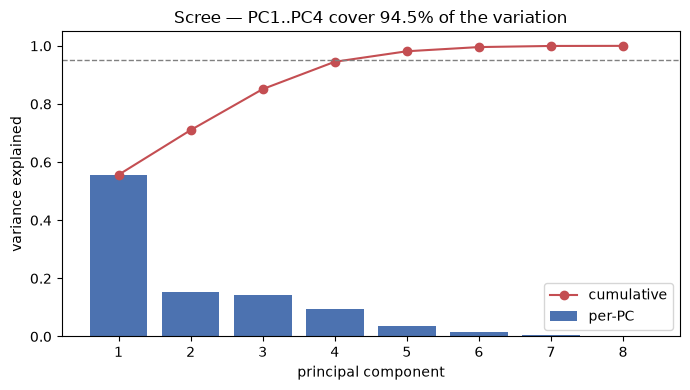

In [7]:
# Scree plot — the elbow after ~4 components.
fig, ax = plt.subplots(figsize=(7, 4))
xs = np.arange(1, len(evr) + 1)
ax.bar(xs, evr, color="#4C72B0", label="per-PC")
ax.plot(xs, np.cumsum(evr), "-o", color="#C44E52", label="cumulative")
ax.axhline(0.95, ls="--", lw=1, color="gray")
ax.set_xlabel("principal component"); ax.set_ylabel("variance explained")
ax.set_title("Scree — PC1..PC4 cover 94.5% of the variation")
ax.set_xticks(xs); ax.legend(); fig.tight_layout()
plt.show()

**Reading it.** Four components cover **94.5%**. Each maps to a survivor family:

| PC | variance | driven by | meaning |
|----|---------:|-----------|---------|
| PC1 | 55.6% | slope / relief / texture | the **ruggedness** bundle |
| PC2 | 15.4% | `mean_elevation` | **altitude** |
| PC3 | 14.1% | **`geomorphon_entropy`** | **landform composition** (its own axis!) |
| PC4 | 9.4% | `elevation_relief_ratio` | **profile shape** (top-heavy vs bottom-heavy) |

`geomorphon_entropy` owning PC3 is the independent confirmation that keeping it is right — no other survivor
covers that direction.

## 4. The decisions (recorded via `/grilling` + `/domain-modeling`)

The measured evidence above narrows the field; the judgement calls below were made with a human and are
recorded here so the notebook stands on its own. **This is a *proposed* vector — the final freeze waits on
B3 (TPI re-entry, #27) and lands in B4 (#28).**

### Surviving metric vector — 6 dims (within the 4–6 target)

| Keep | Role | Evidence |
|------|------|----------|
| `slope_mean` | steepness | representative of the ≥0.90 slope block |
| `local_relief` | vertical scale | ρ 0.81 with slope — under the line; distinct scale axis (first to cut in B4) |
| `texture` | surface roughness | max ρ 0.85, below the line; independent |
| `elevation_relief_ratio` | profile shape | independent; owns PC4 |
| `mean_elevation` | altitude | independent; owns PC2 |
| `geomorphon_entropy` | landform composition | independent; owns PC3; **measured alive** |

### Dropped

| Drop | Why |
|------|-----|
| `slope_std` | inside the ≥0.90 slope block (ρ 0.953) — does not separate from `slope_mean` |
| `normals_dispersion` | inside the ≥0.90 slope block (ρ 0.986) — **redundant; rank-based, so no transform rescues it** |
| `tpi_proxy` | not a survival axis here (prior verdict) — its re-entry is B3's flat-wet call |

### Two carried-in Phase-A verdicts overturned *by measurement*

1. **`normals_dispersion`** — Phase A: "not redundant (curvature not steepness); admit if a transform rescues
   its range." Measured: **0.986** collinear with slope; Spearman is rank-based, so no transform changes that.
   → dropped on **redundancy**, not degeneracy.
2. **`geomorphon_entropy`** — Phase A: "prune on degeneracy (zero-inflated flat tail)." Measured: 0.8% zeros,
   real spread, owns PC3. The degeneracy prediction (formed on flat A3 band-local samples) does not hold on
   this cell-balanced frame. → **kept**.

### Transform set (Iwahashi-minimal) — for the downstream k-means distance only

Spearman is rank-based, so transforms do **not** change anything above; they matter only for the later
clustering step, where a long tail lets a few extreme windows dominate the straight-line distance. We log
exactly the two long-tailed magnitude survivors, per the Iwahashi/Pike precedent:

$$\ln(\text{local\_relief} + 1), \qquad \ln(\text{slope\_mean} + 1)$$

The `+1` is negligible against metres/degrees and safely absorbs the ~0.8% of windows reading exactly 0.
The other four survivors are left untransformed (`elevation_relief_ratio` & `geomorphon_entropy` are the
wrong skew direction; `texture` is a bounded fraction with mild skew; `mean_elevation` has genuine negative
values that break `ln`).

local_relief     skew  raw   3.58  ->  ln(x+1)  -0.29
slope_mean       skew  raw   2.48  ->  ln(x+1)   0.68


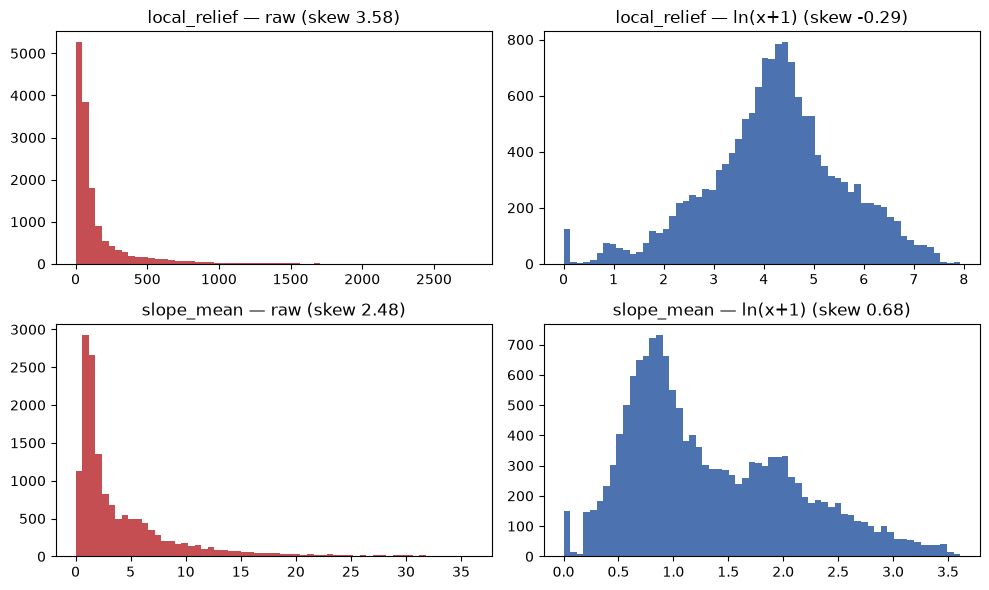

In [8]:
# Show what the two transforms buy: the long right tail collapses toward symmetry.
def skew(v):
    v = v[~np.isnan(v)]
    sd = v.std()
    return float(np.mean(((v - v.mean()) / sd) ** 3)) if sd else np.nan

for m in ("local_relief", "slope_mean"):
    raw = data[m]
    logged = np.log(raw + 1.0)
    print(f"{m:<16} skew  raw {skew(raw):6.2f}  ->  ln(x+1) {skew(logged):6.2f}")

fig, axes = plt.subplots(2, 2, figsize=(10, 6))
for row, m in enumerate(("local_relief", "slope_mean")):
    raw = data[m][~np.isnan(data[m])]
    axes[row, 0].hist(raw, bins=60, color="#C44E52")
    axes[row, 0].set_title(f"{m} — raw (skew {skew(data[m]):.2f})")
    axes[row, 1].hist(np.log(raw + 1.0), bins=60, color="#4C72B0")
    axes[row, 1].set_title(f"{m} — ln(x+1) (skew {skew(np.log(data[m] + 1.0)):.2f})")
fig.tight_layout()
plt.show()

### Proposed answer to #26

**Survivors (6):** `slope_mean`, `local_relief`, `texture`, `elevation_relief_ratio`, `mean_elevation`,
`geomorphon_entropy`.
**Dropped (2, + `tpi_proxy` deferred):** `slope_std`, `normals_dispersion`.
**Transforms:** `ln(local_relief + 1)`, `ln(slope_mean + 1)`.

Proposed, not frozen: **B3 (#27)** tests whether these survivors separate flat-wet from flat-dry and whether
`tpi_proxy` re-enters; **B4 (#28)** freezes the vector and writes ADR-0004.